# BanglaLekha-Isolated: exploratory data analysis

Run locally with your existing `.venv`, or inside the Docker container from `README.md`.
Run cells in order. This dataset contains isolated characters; whole-word recognition
will require additional word images and transcripts.


## 1. Imports and local paths


In [1]:
# Check which Python is executing this notebook before doing any analysis.
import hashlib
import json
import math
import platform
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from PIL import Image, ImageOps
from tqdm.auto import tqdm

print('Python:', sys.executable)
print('System:', platform.system(), '| Architecture:', platform.machine())


Python: /Users/sakibsmacbookm5/Documents/Python work/.venv/bin/python
System: Darwin | Architecture: arm64


/Users/sakibsmacbookm5/Documents/Python work/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Launch Jupyter or VS Code with this project folder as its working directory.
PROJECT_DIR = Path.cwd().resolve()
DATASET_DIR = PROJECT_DIR / 'BanglaLekha-Isolated'
IMAGES_DIR = DATASET_DIR / 'Images'
REPORT_DIR = PROJECT_DIR / 'reports' / 'eda'
SEED = 42

assert IMAGES_DIR.is_dir(), f'Extract the dataset here, or update DATASET_DIR: {DATASET_DIR}'
REPORT_DIR.mkdir(parents=True, exist_ok=True)
print('Project:', PROJECT_DIR)
print('Images:', IMAGES_DIR)
print('Reports:', REPORT_DIR)


Project: /Users/sakibsmacbookm5/Documents/Python work/research-project/SICIP - Assignment 4
Images: /Users/sakibsmacbookm5/Documents/Python work/research-project/SICIP - Assignment 4/BanglaLekha-Isolated/Images
Reports: /Users/sakibsmacbookm5/Documents/Python work/research-project/SICIP - Assignment 4/reports/eda


In [3]:
# Save each graph and still display it in the notebook.
def show_and_save(fig, filename):
    fig.tight_layout()
    fig.savefig(REPORT_DIR / filename, dpi=160, bbox_inches='tight')
    plt.show()
    plt.close(fig)

plt.rcParams.update({'figure.dpi': 100, 'axes.titlesize': 12})
pd.set_option('display.max_columns', 20)


## 2. Dataset structure and class counts


In [4]:
# Read the source description instead of guessing the filename fields.
readme = DATASET_DIR / 'Readme.txt'
if readme.exists():
    print(readme.read_text(errors='replace'))

class_folders = sorted(
    [folder for folder in IMAGES_DIR.iterdir() if folder.is_dir() and folder.name.isdigit()],
    key=lambda folder: int(folder.name),  # Numeric order: 1, 2, ..., 84.
)
print('Class folders:', len(class_folders))
print('Other dataset files:', [p.name for p in DATASET_DIR.iterdir() if p.is_file()])


Under the "Images" folder you should see 84 folders numbered 1 to 84. 

Under each folder you should find file names with the following format

01_0001_0_08_0916_1990_1.png

where:

The first 2 digits indicate the district from which the sample was collected. There are only two districts currently.

The next  4 digits are an institution identifier (the institution from which the sample was collected).

The next  1 digit signifies the gender of the subject giving the sample. 0 for male, 1 for female.

The next  2 digits holds the age of the subject giving the sample.

The next  4 digits shows the month and day of the year 2016 on which the sample was collected.

The next  4 digits is the serial number of the form which was used the collect the sample.

The next  1 digit is the character class of the sample (there are 84 classes). This number should match the directory name.



Class folders: 84
Other dataset files: ['Form-based Marking.xlsx', 'Readme.txt']


In [5]:
# Store paths and labels, not all image arrays, to keep RAM usage low.
extensions = {'.png', '.jpg', '.jpeg', '.bmp'}
records = [
    {'path': path.relative_to(DATASET_DIR).as_posix(),
     'class_id': int(folder.name), 'stem': path.stem}
    for folder in class_folders
    for path in sorted(folder.iterdir())
    if path.is_file() and path.suffix.lower() in extensions
]
files_df = pd.DataFrame(records)
assert not files_df.empty, 'No supported image files were found.'
assert files_df['path'].is_unique, 'Repeated image paths in the inventory.'
print('Total images:', len(files_df))
display(files_df.head())


Total images: 166105


,path,class_id,stem
0,Images/1/01_0001_0_08_0916_1990_1.png,1,01_0001_0_08_0916_1990_1
1,Images/1/01_0001_0_11_0916_1913_1.png,1,01_0001_0_11_0916_1913_1
2,Images/1/01_0001_0_11_0916_1917_1.png,1,01_0001_0_11_0916_1917_1
3,Images/1/01_0001_0_11_0916_1918_1.png,1,01_0001_0_11_0916_1918_1
4,Images/1/01_0001_0_11_0916_1919_1.png,1,01_0001_0_11_0916_1919_1


In [6]:
# Reindex so an empty class folder is also visible in the report.
class_counts = files_df.groupby('class_id').size().reindex(
    [int(folder.name) for folder in class_folders], fill_value=0,
).rename('image_count')
class_table = class_counts.reset_index()
display(class_table)
print('Smallest/largest class:', int(class_counts.min()), '/', int(class_counts.max()))
if class_counts.min() > 0:
    print('Largest/smallest ratio:', round(class_counts.max() / class_counts.min(), 3))
print('Expected class IDs present:', set(class_counts.index) == set(range(1, 85)))


,class_id,image_count
0,1,1975
1,2,1980
2,3,1979
3,4,1982
4,5,1982
...,...,...
79,80,1980
80,81,1975
81,82,1978
82,83,1971


Smallest/largest class: 1940 / 1988
Largest/smallest ratio: 1.025
Expected class IDs present: True


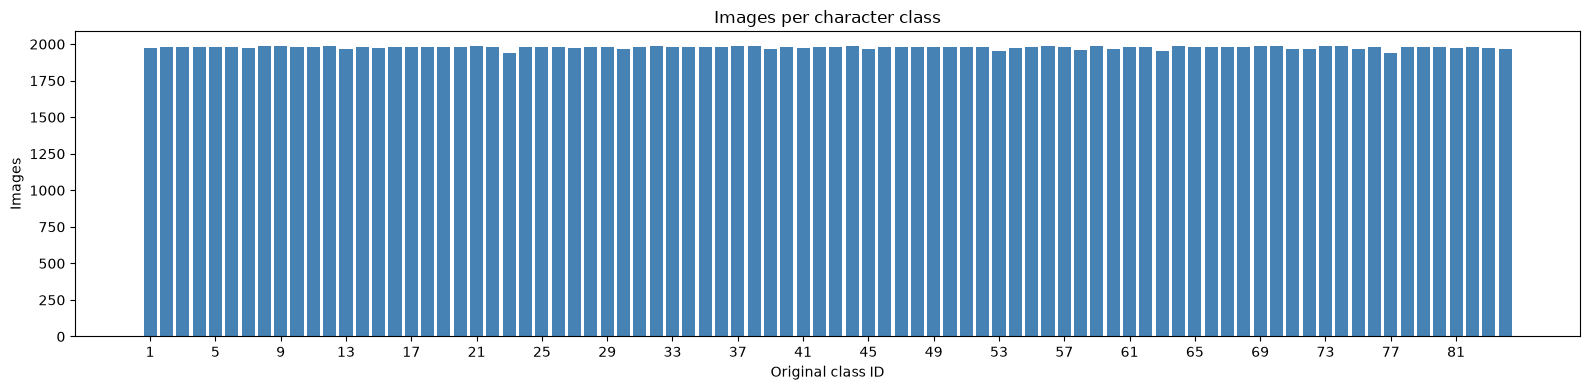

In [7]:
# Keep the official numeric labels; an unverified Bangla label map could mislabel classes.
fig, ax = plt.subplots(figsize=(16, 4))
ax.bar(class_counts.index, class_counts.values, color='steelblue')
ax.set(xlabel='Original class ID', ylabel='Images', title='Images per character class')
ax.set_xticks(class_counts.index[::4])
show_and_save(fig, '01_class_balance.png')


## 3. View the handwriting


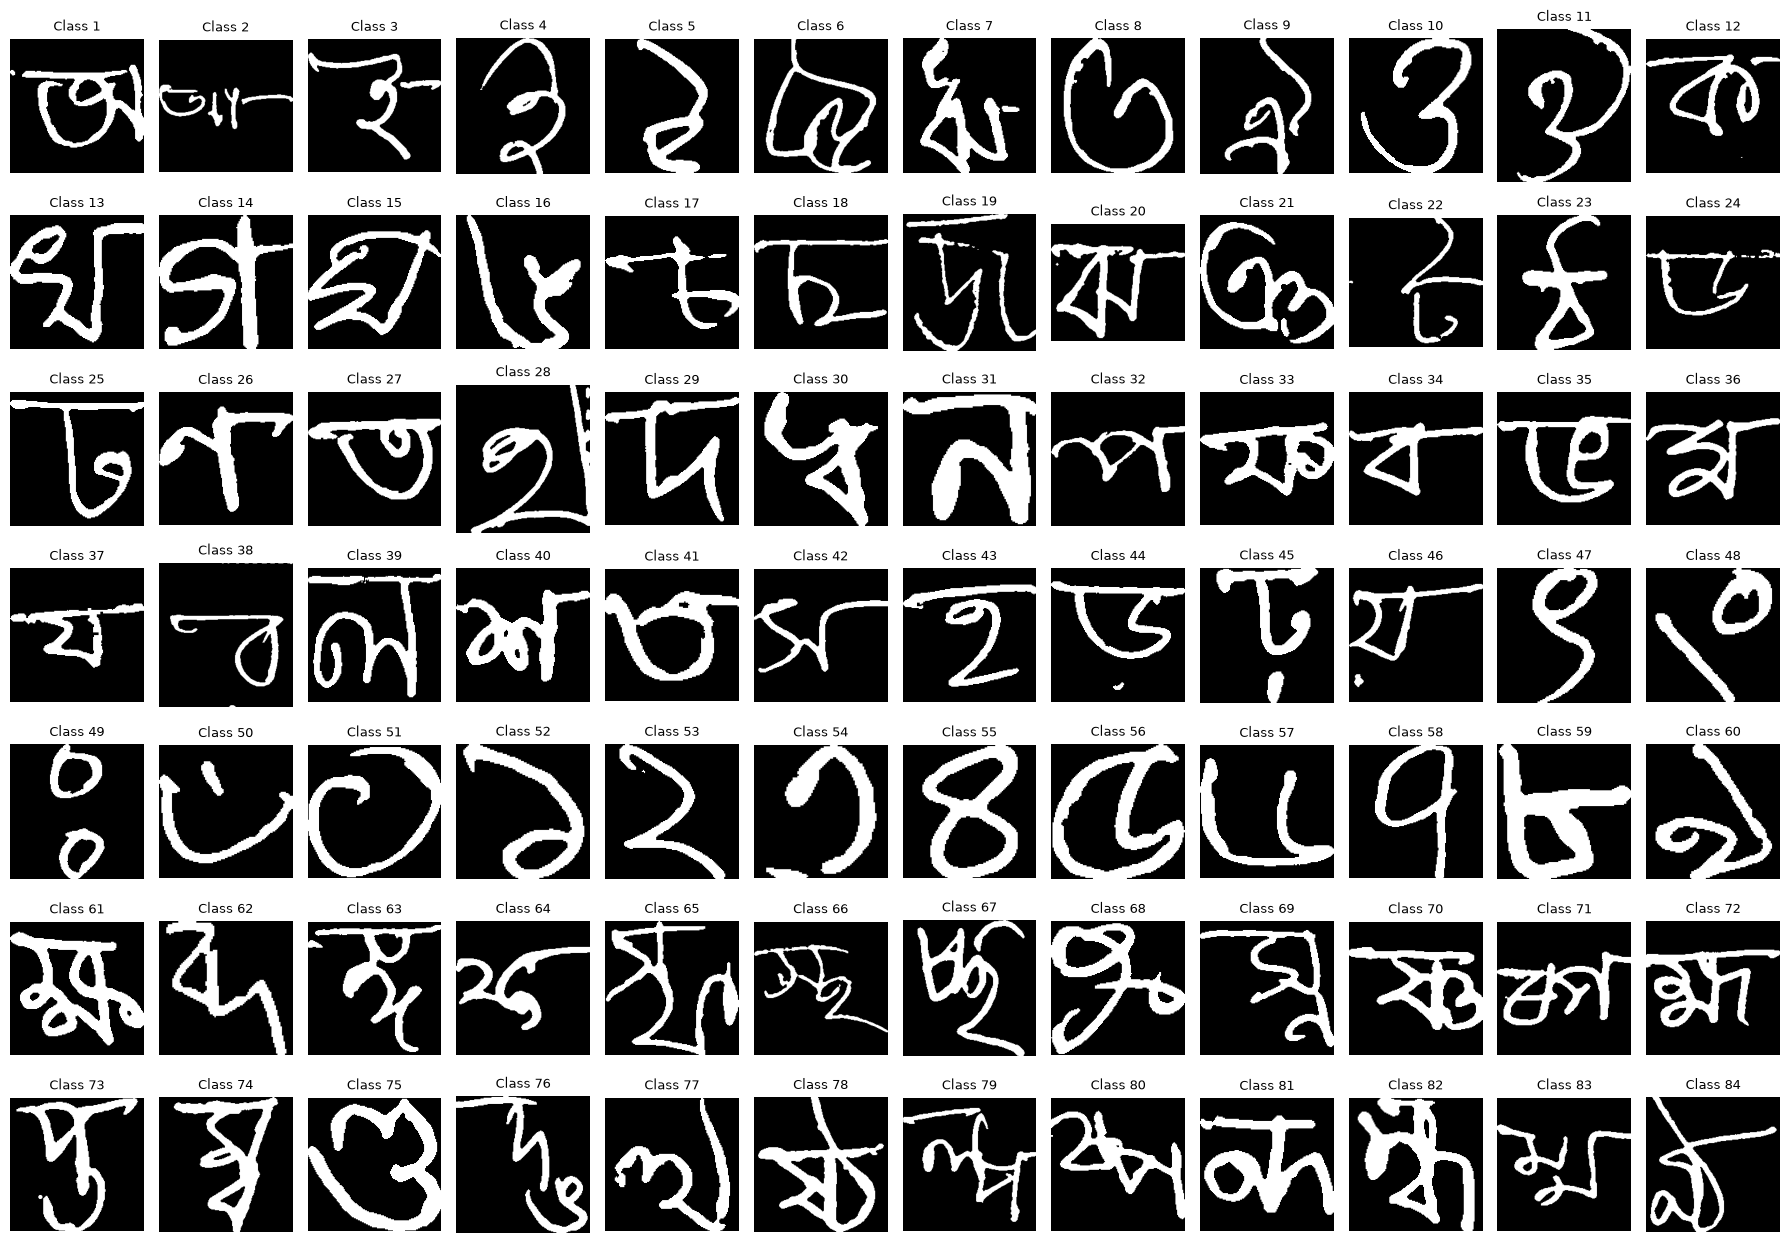

In [8]:
# One reproducible example per class reveals the actual image style and polarity.
examples = files_df.groupby('class_id').sample(n=1, random_state=SEED).sort_values('class_id')
columns = 12
rows = math.ceil(len(examples) / columns)
fig, axes = plt.subplots(rows, columns, figsize=(18, rows * 1.8), squeeze=False)

for ax, row in zip(axes.flat, examples.itertuples(index=False)):
    try:
        with Image.open(DATASET_DIR / row.path) as image:
            ax.imshow(image.convert('L'), cmap='gray', vmin=0, vmax=255)
    except (OSError, ValueError):
        ax.text(0.5, 0.5, 'Unreadable', ha='center', va='center')
    ax.set_title(f'Class {row.class_id}', fontsize=9)
    ax.axis('off')
for ax in list(axes.flat)[len(examples):]:
    ax.axis('off')
show_and_save(fig, '02_class_examples.png')


## 4. Filename metadata

The README encodes district, institution, gender, age, collection code, form serial
and class. A form ID identifies a collection form, not a guaranteed unique writer.


In [9]:
# Validate the documented seven-field pattern before using its metadata.
pattern = (
    r'^(?P<district_id>\d{2})_(?P<institution_id>\d{4})_'
    r'(?P<gender_code>\d)_(?P<age>\d{2})_(?P<collection_code>\d{4})_'
    r'(?P<form_serial>\d{4})_(?P<class_from_filename>\d{1,2})$'
)
metadata = files_df['stem'].str.extract(pattern)
files_df = pd.concat([files_df, metadata], axis=1)
files_df['age'] = pd.to_numeric(files_df['age'], errors='coerce').astype('Int64')
name_classes = pd.to_numeric(files_df['class_from_filename'], errors='coerce')
files_df['filename_ok'] = (metadata.notna().all(axis=1) & name_classes.eq(files_df['class_id'])).fillna(False)

# Include all six prefix fields; a serial alone may not identify a form globally.
files_df['form_id'] = files_df['stem'].str.rsplit('_', n=1).str[0]
filename_issues = files_df.loc[~files_df['filename_ok']].copy()
print('Invalid filenames / mismatched class IDs:', len(filename_issues))
display(filename_issues.head())


Invalid filenames / mismatched class IDs: 47


,path,class_id,stem,district_id,institution_id,gender_code,age,collection_code,form_serial,class_from_filename,filename_ok,form_id
145175,Images/74/02_0002_0_11_1016_0699_75.png,74,02_0002_0_11_1016_0699_75,02,0002,0,11,1016,0699,75,False,02_0002_0_11_1016_0699
145234,Images/74/02_0002_0_18_1016_0664_75.png,74,02_0002_0_18_1016_0664_75,02,0002,0,18,1016,0664,75,False,02_0002_0_18_1016_0664
145235,Images/74/02_0002_0_18_1016_0665_75.png,74,02_0002_0_18_1016_0665_75,02,0002,0,18,1016,0665,75,False,02_0002_0_18_1016_0665
145411,Images/74/02_0002_0_20_1016_0668_75.png,74,02_0002_0_20_1016_0668_75,02,0002,0,20,1016,0668,75,False,02_0002_0_20_1016_0668
145412,Images/74/02_0002_0_20_1016_0669_75.png,74,02_0002_0_20_1016_0669_75,02,0002,0,20,1016,0669,75,False,02_0002_0_20_1016_0669


In [10]:
# Count demographic metadata once per form, rather than once per character image.
valid_metadata = files_df.loc[files_df['filename_ok']].copy()
forms = valid_metadata.drop_duplicates('form_id')
form_coverage = valid_metadata.groupby('form_id')['class_id'].nunique()
print('Collection forms:', len(forms))
print('Forms with all 84 classes:', int(form_coverage.eq(84).sum()))
display(forms[['form_id', 'district_id', 'institution_id', 'gender_code', 'age']].head())
display(form_coverage.describe().rename('classes_per_form').to_frame())


Collection forms: 1990
Forms with all 84 classes: 1516


,form_id,district_id,institution_id,gender_code,age
0,01_0001_0_08_0916_1990,01,0001,0,8
1,01_0001_0_11_0916_1913,01,0001,0,11
2,01_0001_0_11_0916_1917,01,0001,0,11
3,01_0001_0_11_0916_1918,01,0001,0,11
4,01_0001_0_11_0916_1919,01,0001,0,11


,classes_per_form
count,1990.000000
mean,83.446231
std,3.143281
min,1.000000
25%,84.000000
50%,84.000000
75%,84.000000
max,84.000000


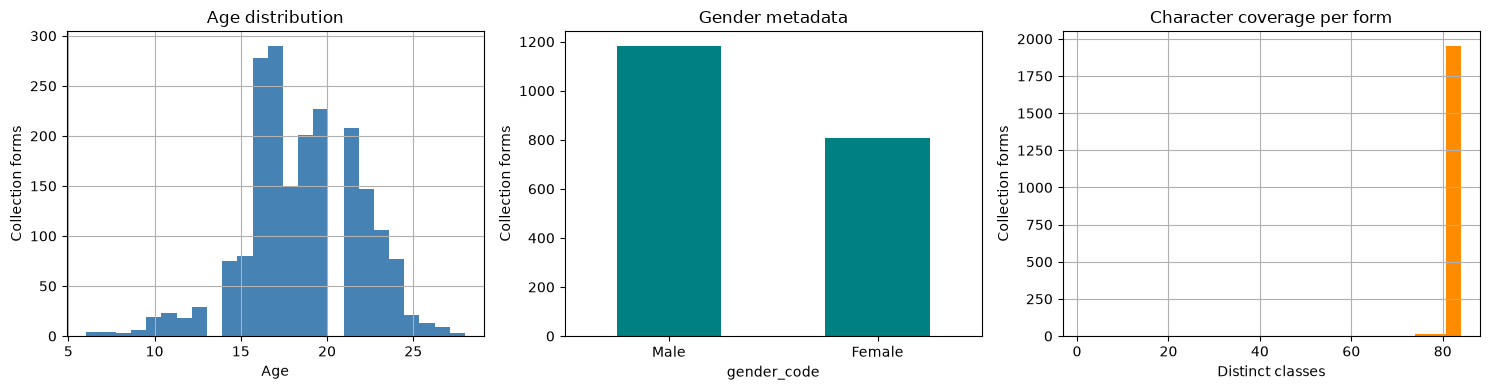

In [11]:
# These plots describe the source population and missing character coverage.
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
forms['age'].dropna().astype(int).hist(ax=axes[0], bins=25, color='steelblue')
axes[0].set(xlabel='Age', ylabel='Collection forms', title='Age distribution')
gender_counts = forms['gender_code'].map({'0': 'Male', '1': 'Female'}).fillna('Unknown').value_counts()
gender_counts.plot.bar(ax=axes[1], color='teal', rot=0)
axes[1].set(ylabel='Collection forms', title='Gender metadata')
form_coverage.hist(ax=axes[2], bins=25, color='darkorange')
axes[2].set(xlabel='Distinct classes', ylabel='Collection forms', title='Character coverage per form')
show_and_save(fig, '03_form_metadata.png')


## 5. Image quality and dimensions

Full scanning is enabled. Set `FULL_SCAN=False` for a reproducible sample.
Blank flags are review heuristics; this notebook does not delete or clean images.


In [12]:
# Metadata counts above always cover every file. Pixel findings cover this scan only.
FULL_SCAN = True
SCAN_SAMPLE_SIZE = 3000
scan_files = files_df if FULL_SCAN else files_df.sample(
    n=min(SCAN_SAMPLE_SIZE, len(files_df)), random_state=SEED,
)
print('Scan mode:', 'full dataset' if FULL_SCAN else 'sample')
print('Images to decode:', len(scan_files))


Scan mode: full dataset
Images to decode: 166105


In [13]:
def inspect_image(path):
    # Decode one image at a time. Hash decoded grayscale pixels, not PNG metadata.
    with Image.open(path) as image:
        image.load()
        mode = image.mode
        array = np.asarray(ImageOps.exif_transpose(image).convert('L'), dtype=np.uint8)
    height, width = array.shape
    border = np.concatenate([array[0], array[-1], array[:, 0], array[:, -1]])
    light_background = float(np.median(border)) > 127
    ink = 255 - array if light_background else array
    foreground = ink > 32  # A simple intensity threshold for descriptive statistics.
    ys, xs = np.where(foreground)
    pixel_hash = hashlib.sha256(f'{width}x{height}:'.encode() + array.tobytes()).hexdigest()
    return {
        'width': width, 'height': height, 'mode': mode,
        'aspect_ratio': width / height,
        'mean_intensity': float(array.mean()), 'std_intensity': float(array.std()),
        'border_median': float(np.median(border)),
        'polarity': 'dark ink / light background' if light_background else 'light ink / dark background',
        'foreground_fraction': float(foreground.mean()),
        'near_blank': not foreground.any() or int(array.max()) - int(array.min()) < 16,
        'ink_width': int(xs.max() - xs.min() + 1) if len(xs) else 0,
        'ink_height': int(ys.max() - ys.min() + 1) if len(ys) else 0,
        'pixel_sha256': pixel_hash,
    }


In [14]:
# Record failures so one damaged file does not stop inspection of the entire dataset.
image_records, errors = [], []
started = time.perf_counter()
for row in tqdm(scan_files.itertuples(index=False), total=len(scan_files), desc='Inspecting images'):
    try:
        stats = inspect_image(DATASET_DIR / row.path)
        image_records.append({'path': row.path, 'class_id': row.class_id, 'form_id': row.form_id, **stats})
    except (OSError, ValueError, SyntaxError) as error:
        errors.append({'path': row.path, 'error': str(error)})

image_stats = pd.DataFrame(image_records)
decode_errors = pd.DataFrame(errors, columns=['path', 'error'])
scan_seconds = time.perf_counter() - started
assert not image_stats.empty, 'No images decoded successfully; inspect decode_errors.'
print(f'Scanned in {scan_seconds:.1f}s | decoded: {len(image_stats)} | errors: {len(decode_errors)}')
display(decode_errors.head())


Inspecting images: 100%|██████████| 166105/166105 [00:45<00:00, 3626.54it/s]


Scanned in 46.0s | decoded: 166105 | errors: 0


,path,error


In [15]:
# Size and intensity summaries help choose later model input sizes and preprocessing.
numeric_columns = ['width', 'height', 'aspect_ratio', 'mean_intensity', 'foreground_fraction']
display(image_stats[numeric_columns].describe().round(3))
print('Image modes:', image_stats['mode'].value_counts().to_dict())
print('Observed polarity:', image_stats['polarity'].value_counts().to_dict())
print('Near-blank flags:', int(image_stats['near_blank'].sum()))


,width,height,aspect_ratio,mean_intensity,foreground_fraction
count,166105.000,166105.000,166105.000,166105.000,166105.000
mean,151.551,151.871,0.998,46.903,0.184
std,35.730,35.766,0.036,16.120,0.063
min,26.000,25.000,0.458,0.201,0.001
25%,125.000,126.000,1.000,35.370,0.139
50%,150.000,151.000,1.000,45.036,0.177
75%,176.000,177.000,1.006,56.597,0.222
max,382.000,389.000,2.662,160.525,0.630


Image modes: {'L': 166105}
Observed polarity: {'light ink / dark background': 166105}
Near-blank flags: 0


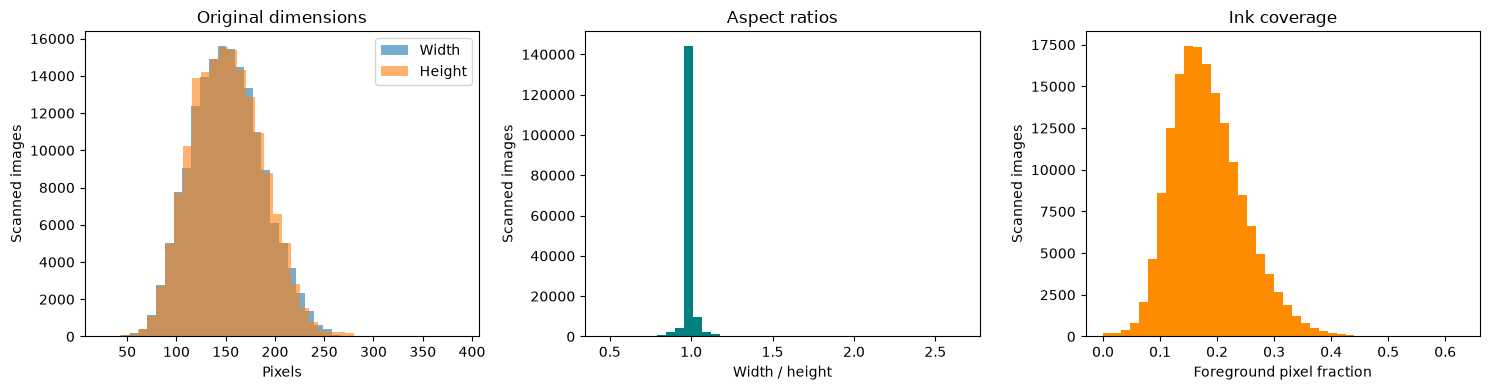

In [16]:
# Images have different sizes; preserve aspect ratios when designing preprocessing.
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(image_stats['width'], bins=40, alpha=0.6, label='Width')
axes[0].hist(image_stats['height'], bins=40, alpha=0.6, label='Height')
axes[0].set(xlabel='Pixels', ylabel='Scanned images', title='Original dimensions')
axes[0].legend()
axes[1].hist(image_stats['aspect_ratio'], bins=40, color='teal')
axes[1].set(xlabel='Width / height', ylabel='Scanned images', title='Aspect ratios')
axes[2].hist(image_stats['foreground_fraction'], bins=40, color='darkorange')
axes[2].set(xlabel='Foreground pixel fraction', ylabel='Scanned images', title='Ink coverage')
show_and_save(fig, '04_image_statistics.png')


## 6. Exact duplicates and flagged examples


In [17]:
# Exact matching includes image dimensions. Resized/cropped near-duplicates are not detected.
duplicates = image_stats.loc[image_stats.duplicated('pixel_sha256', keep=False)].copy()
duplicate_sizes = duplicates.groupby('pixel_sha256').size()
conflicting_hashes = duplicates.groupby('pixel_sha256')['class_id'].nunique()
conflicting_hashes = conflicting_hashes.loc[conflicting_hashes > 1].index
conflicting_duplicates = duplicates.loc[duplicates['pixel_sha256'].isin(conflicting_hashes)]

print('Exact duplicate groups:', len(duplicate_sizes))
print('Images in duplicate groups:', len(duplicates))
print('Redundant copies beyond one per group:', int((duplicate_sizes - 1).sum()))
print('Images in groups with conflicting class labels:', len(conflicting_duplicates))
display(duplicates[['path', 'class_id', 'form_id', 'pixel_sha256']].head(10))


Exact duplicate groups: 717
Images in duplicate groups: 1457
Redundant copies beyond one per group: 740
Images in groups with conflicting class labels: 1133


,path,class_id,form_id,pixel_sha256
1368,Images/1/02_0002_0_23_1016_0992_1.png,1,02_0002_0_23_1016_0992,559379d732d0f38ab0ddc3ec5214d44df975c86ab63fc1...
1434,Images/1/02_0002_0_24_1016_0993_1.png,1,02_0002_0_24_1016_0993,559379d732d0f38ab0ddc3ec5214d44df975c86ab63fc1...
1435,Images/1/02_0002_0_24_1016_0994_1.png,1,02_0002_0_24_1016_0994,76943392c8a2f711c8ab1d911c16b16b2f6d0cce102964...
1968,Images/1/02_0002_1_25_1016_0990_1.png,1,02_0002_1_25_1016_0990,08b9e22990124fbc944f7e4fcadae2f34cf33aa017bc28...
1969,Images/1/02_0002_1_25_1016_0991_1.png,1,02_0002_1_25_1016_0991,08b9e22990124fbc944f7e4fcadae2f34cf33aa017bc28...
2266,Images/2/01_0001_0_17_0916_0261_2.png,2,01_0001_0_17_0916_0261,46447847da18437dfb0ee39de2487cc6cb8e9040772e93...
2489,Images/2/01_0001_1_16_0916_0286_2.png,2,01_0001_1_16_0916_0286,46447847da18437dfb0ee39de2487cc6cb8e9040772e93...
3346,Images/2/02_0002_0_23_1016_0992_2.png,2,02_0002_0_23_1016_0992,c46b66dd023d912ccc2840ff70ffb911c977f7aa76a8ec...
3413,Images/2/02_0002_0_24_1016_0993_2.png,2,02_0002_0_24_1016_0993,c46b66dd023d912ccc2840ff70ffb911c977f7aa76a8ec...
3414,Images/2/02_0002_0_24_1016_0994_2.png,2,02_0002_0_24_1016_0994,76943392c8a2f711c8ab1d911c16b16b2f6d0cce102964...


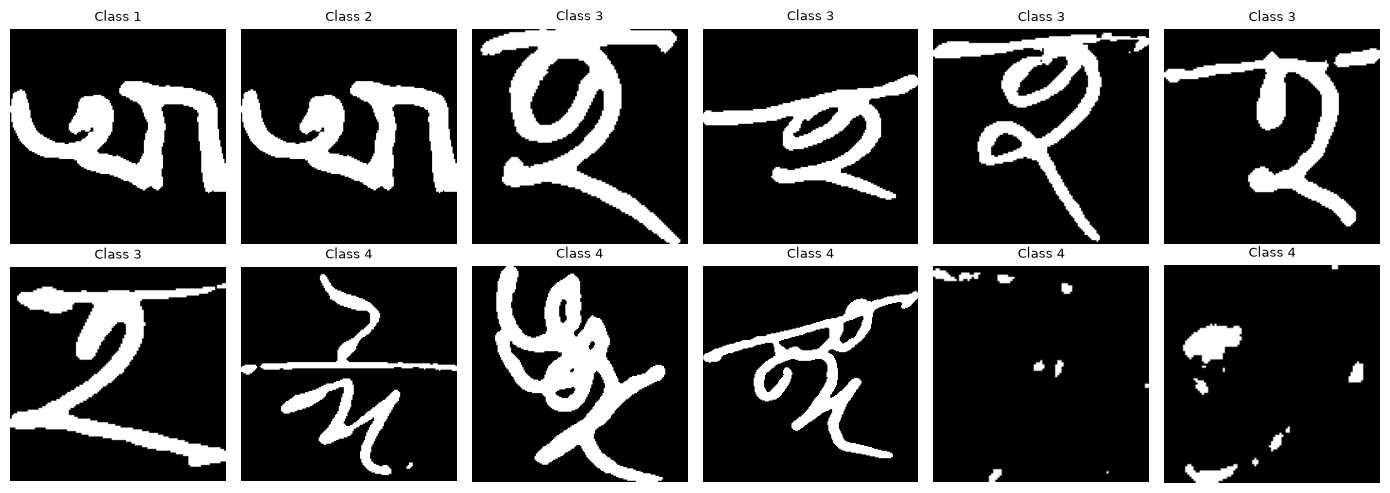

In [18]:
# Review near-blank images and conflicting duplicate labels before future training.
flagged = pd.concat([
    image_stats.loc[image_stats['near_blank']], conflicting_duplicates,
]).drop_duplicates('path').head(12)

if not flagged.empty:
    fig, axes = plt.subplots(2, 6, figsize=(14, 5), squeeze=False)
    for ax, row in zip(axes.flat, flagged.itertuples(index=False)):
        with Image.open(DATASET_DIR / row.path) as image:
            ax.imshow(image.convert('L'), cmap='gray', vmin=0, vmax=255)
        ax.set_title(f'Class {row.class_id}', fontsize=9)
    for ax in axes.flat:
        ax.axis('off')
    show_and_save(fig, '05_flagged_examples.png')
else:
    print('No blank/conflicting-duplicate flags in this scan.')


## 7. Save reports and findings


In [19]:
# CSVs keep paths and measurements available for review without rerunning the scan.
files_df.to_csv(REPORT_DIR / 'file_inventory.csv', index=False)
class_table.to_csv(REPORT_DIR / 'class_counts.csv', index=False)
forms.to_csv(REPORT_DIR / 'collection_forms.csv', index=False)
form_coverage.to_csv(REPORT_DIR / 'form_coverage.csv')
filename_issues.to_csv(REPORT_DIR / 'filename_issues.csv', index=False)
image_stats.to_csv(REPORT_DIR / 'image_statistics.csv', index=False)
decode_errors.to_csv(REPORT_DIR / 'decode_errors.csv', index=False)
duplicates.to_csv(REPORT_DIR / 'exact_duplicates.csv', index=False)
conflicting_duplicates.to_csv(REPORT_DIR / 'conflicting_duplicates.csv', index=False)
examples[['class_id', 'path']].to_csv(REPORT_DIR / 'class_example_paths.csv', index=False)


In [20]:
# Keep scan scope explicit so sample results are never mistaken for full-dataset results.
summary = {
    'total_image_files': len(files_df), 'class_folders': len(class_folders),
    'smallest_class': int(class_counts.min()), 'largest_class': int(class_counts.max()),
    'collection_forms': len(forms), 'filename_issues': len(filename_issues),
    'scan_scope': 'full' if FULL_SCAN else 'sample', 'scan_requested': len(scan_files),
    'decoded_images': len(image_stats), 'decode_errors': len(decode_errors),
    'near_blank_flags': int(image_stats['near_blank'].sum()),
    'exact_duplicate_groups': len(duplicate_sizes),
    'redundant_exact_copies': int((duplicate_sizes - 1).sum()),
    'conflicting_duplicate_rows': len(conflicting_duplicates),
    'scan_seconds': round(scan_seconds, 2),
    'python_version': platform.python_version(), 'platform': platform.system(),
    'dataset_type': 'isolated characters; no whole-word transcripts',
}
(REPORT_DIR / 'summary.json').write_text(json.dumps(summary, indent=2), encoding='utf-8')
display(pd.Series(summary, name='EDA summary'))
print('Reports saved to:', REPORT_DIR)


total_image_files                                                     166105
class_folders                                                             84
smallest_class                                                          1940
largest_class                                                           1988
collection_forms                                                        1990
filename_issues                                                           47
scan_scope                                                              full
scan_requested                                                        166105
decoded_images                                                        166105
decode_errors                                                              0
near_blank_flags                                                           0
exact_duplicate_groups                                                   717
redundant_exact_copies                                                   740

Reports saved to: /Users/sakibsmacbookm5/Documents/Python work/research-project/SICIP - Assignment 4/reports/eda
